# Лабораторна робота № 1. Апроксимація та інтерполяція функцій

**Варіант 23.** Курс «Основи цифрової обробки сигналів», Серафін Д.А., ІР-43.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/serafindanyil/digital-signal-processing/blob/lab-1/lab-1/lab_1.ipynb)

Обчислення написані в модулях `lab-1/*.py`. Тут я тільки викликаю їх, друкую результати і будую графік.

## Налаштування середовища

У Google Colab спершу клонуємо гілку `lab-1` репозиторію, а локально просто знаходимо його корінь. Після цього папка `lab-1` додається до `sys.path`, щоб працював імпорт модулів. NumPy, SciPy і matplotlib у Colab вже є.

In [1]:
import sys, subprocess
from pathlib import Path
if "google.colab" in sys.modules:
    if not Path("digital-signal-processing").exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", "lab-1",
                        "https://github.com/serafindanyil/digital-signal-processing.git"], check=True)
    repo_root = Path("digital-signal-processing").resolve()
else:
    repo_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
sys.path.insert(0, str(repo_root / "lab-1"))

In [2]:
import matplotlib.pyplot as plt
from IPython.display import display

import main as lab

## Вихідні дані варіанту

Пари вимірювань xₙ, yₙ з таблиці «Завдання 1»: N = 8, крок hₙ = 0,1. Дані записані тільки у `variant_data.py`, тому блокнот і `main.py` беруть однакові числа.

In [3]:
lab.print_variant_data()

Variant 23, N = 8
n   :    1     2     3     4     5     6     7     8
x_n :  0.1   0.2   0.3   0.4   0.5   0.6   0.7   0.8
y_n :  1.0   2.0   2.0   3.0   3.0   4.0   4.0   5.0


## 1. Апроксимуючий поліном P(x) = a + bx + cx², ручний розрахунок

Шукаємо коефіцієнти, при яких S = Σ(P(xₙ) − yₙ)² (вираз 6) найменша. Після прирівнювання частинних похідних до нуля (7–8) виходить нормальна система (9); для полінома другого порядку (d = 0) вона має вигляд (10). Суми я рахую в дробах, щоб не було округлень, а систему розв’язую методом Крамера.

In [4]:
polynomial_hand = lab.solve_polynomial_by_hand()
lab.print_polynomial_by_hand(polynomial_hand)

Sums for the normal equations (exact):
  N        = 8
  Σx^1      =         18/5 =     3.600000
  Σx^2      =        51/25 =     2.040000
  Σx^3      =      162/125 =     1.296000
  Σx^4      =    2193/2500 =     0.877200
  Σx^0·y    =           24 =    24.000000
  Σx^1·y    =           13 =    13.000000
  Σx^2·y    =        81/10 =     8.100000
System (10):
    8.000000    3.600000    2.040000  |  24.000000
    3.600000    2.040000    1.296000  |  13.000000
    2.040000    1.296000    0.877200  |   8.100000
Cramer's rule:
  Δ   =    882/15625 =     0.056448
  Δa  =    567/15625 =     0.036288   →   a = Δa/Δ =         9/14 =     0.642857
  Δb  =     924/3125 =     0.295680   →   b = Δb/Δ =       110/21 =     5.238095
  Δc  =            0 =     0.000000   →   c = Δc/Δ =            0 =     0.000000
P(x) = 0.642857 + 5.238095·x + 0.000000·x²
P(x_n) : 1.166667  1.690476  2.214286  2.738095  3.261905  3.785714  4.309524  4.833333
Residual sum of squares S = 0.476190


## 1. Перевірка функцією `np.polyfit`

`np.polyfit(x, y, 2)` будує той самий поліном методом найменших квадратів. Порівнюємо коефіцієнти і значення полінома на густій сітці.

In [5]:
polynomial_library = lab.solve_polynomial_by_library()
polynomial_comparison = lab.compare_polynomials(polynomial_hand, polynomial_library)
lab.print_polynomial_by_library(polynomial_library, polynomial_comparison)

np.polyfit(x, y, 2) → a = 0.642857  b = 5.238095  c = 0.000000
max |hand − polyfit| (coefficients) = 7.105e-15
max |hand − polyfit| (curve)        = 1.776e-15


## 2. Звичайний кубічний сплайн, ручний розрахунок

На кожному інтервалі Pₙ(x) = aₙ + bₙ(x − xₙ) + cₙ(x − xₙ)² + dₙ(x − xₙ)³ (вираз 12), де hₙ = xₙ₊₁ − xₙ (13). Сплайн звичайний, тому на кінцях y″₁ = y″₈ = 0. Другі похідні у внутрішніх точках знаходимо з тридіагональної системи (26) методом прогонки, а коефіцієнти рахуємо за виразами (20)–(23).

In [6]:
spline_hand = lab.solve_spline_by_hand()
lab.print_spline_by_hand(spline_hand)

Steps h_n: 0.1  0.1  0.1  0.1  0.1  0.1  0.1
System (26) for y″_2 … y″_7 (y″_1 = y″_8 = 0):
   0.4   0.1   0.0   0.0   0.0   0.0  |   -60.00
   0.1   0.4   0.1   0.0   0.0   0.0  |    60.00
   0.0   0.1   0.4   0.1   0.0   0.0  |   -60.00
   0.0   0.0   0.1   0.4   0.1   0.0  |    60.00
   0.0   0.0   0.0   0.1   0.4   0.1  |   -60.00
   0.0   0.0   0.0   0.0   0.1   0.4  |    60.00
y″_n : 0.000000  -219.512195  278.048780  -292.682927  292.682927  -278.048780  219.512195  0.000000
    interval        a_n          b_n            c_n            d_n
[0.1; 0.2]   1.000000    13.658537       0.000000    -365.853659
[0.2; 0.3]   2.000000     2.682927    -109.756098     829.268293
[0.3; 0.4]   2.000000     5.609756     139.024390    -951.219512
[0.4; 0.5]   3.000000     4.878049    -146.341463     975.609756
[0.5; 0.6]   3.000000     4.878049     146.341463    -951.219512
[0.6; 0.7]   4.000000     5.609756    -139.024390     829.268293
[0.7; 0.8]   4.000000     2.682927     109.756098    -36

## 2. Перевірка функцією `CubicSpline`

`scipy.interpolate.CubicSpline(x, y, bc_type="natural")` будує звичайний сплайн з такими ж крайовими умовами.

In [7]:
spline_library = lab.solve_spline_by_library()
spline_comparison = lab.compare_splines(spline_hand, spline_library)
lab.print_spline_by_library(spline_library, spline_comparison)

CubicSpline(x, y, bc_type="natural") second derivatives:
  0.000000  -219.512195  278.048780  -292.682927  292.682927  -278.048780  219.512195  0.000000
max |hand − CubicSpline| (y″)           = 5.684e-14
max |hand − CubicSpline| (a, b, c, d)   = 2.842e-13
max |hand − CubicSpline| (curve)        = 1.332e-15
max |spline(x_n) − y_n|                 = 0.000e+00


## 3. Графік функції, апроксимуючого полінома та сплайну

Ручний розрахунок показано суцільними лініями, а `np.polyfit` і `CubicSpline` пунктиром поверх них. Рисунок також зберігається у `lab-1/figures/` (180 dpi).

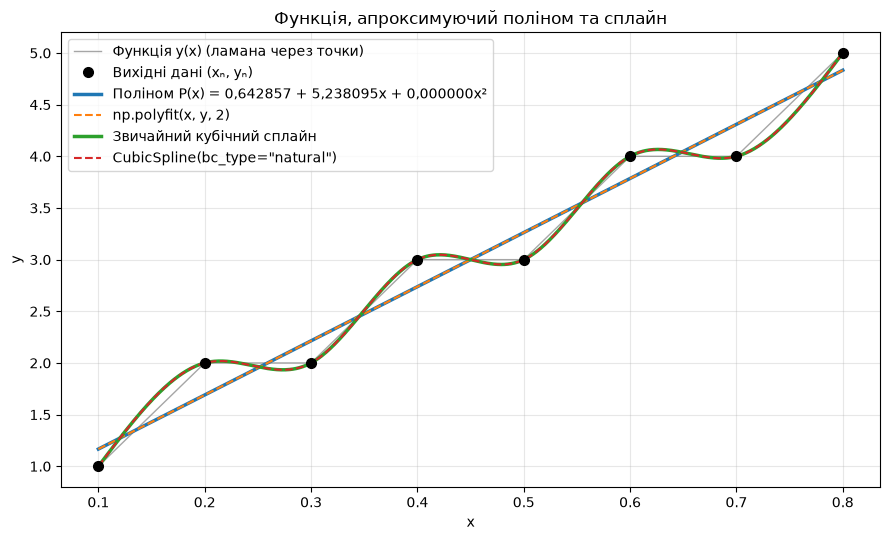

In [8]:
figures = lab.build_figures(polynomial_hand, polynomial_library, spline_hand, spline_library)
lab.save_figures(figures)
for figure in figures.values():
    display(figure)
    plt.close(figure)

## Підсумок

Коефіцієнти полінома відрізняються від `np.polyfit` не більше ніж на 7,1·10⁻¹⁵, коефіцієнти сплайну від `CubicSpline` не більше ніж на 2,8·10⁻¹³. Сплайн проходить через усі вісім точок.

In [9]:
lab.print_summary(polynomial_hand, polynomial_comparison, spline_comparison)

P(x) = 0.642857 + 5.238095·x + 0.000000·x²  (a = 9/14, b = 110/21, c = 0)
Largest |hand − library| difference: 2.842e-13
Spline passes through all samples: max error 0.000e+00
